# Constructing Networks

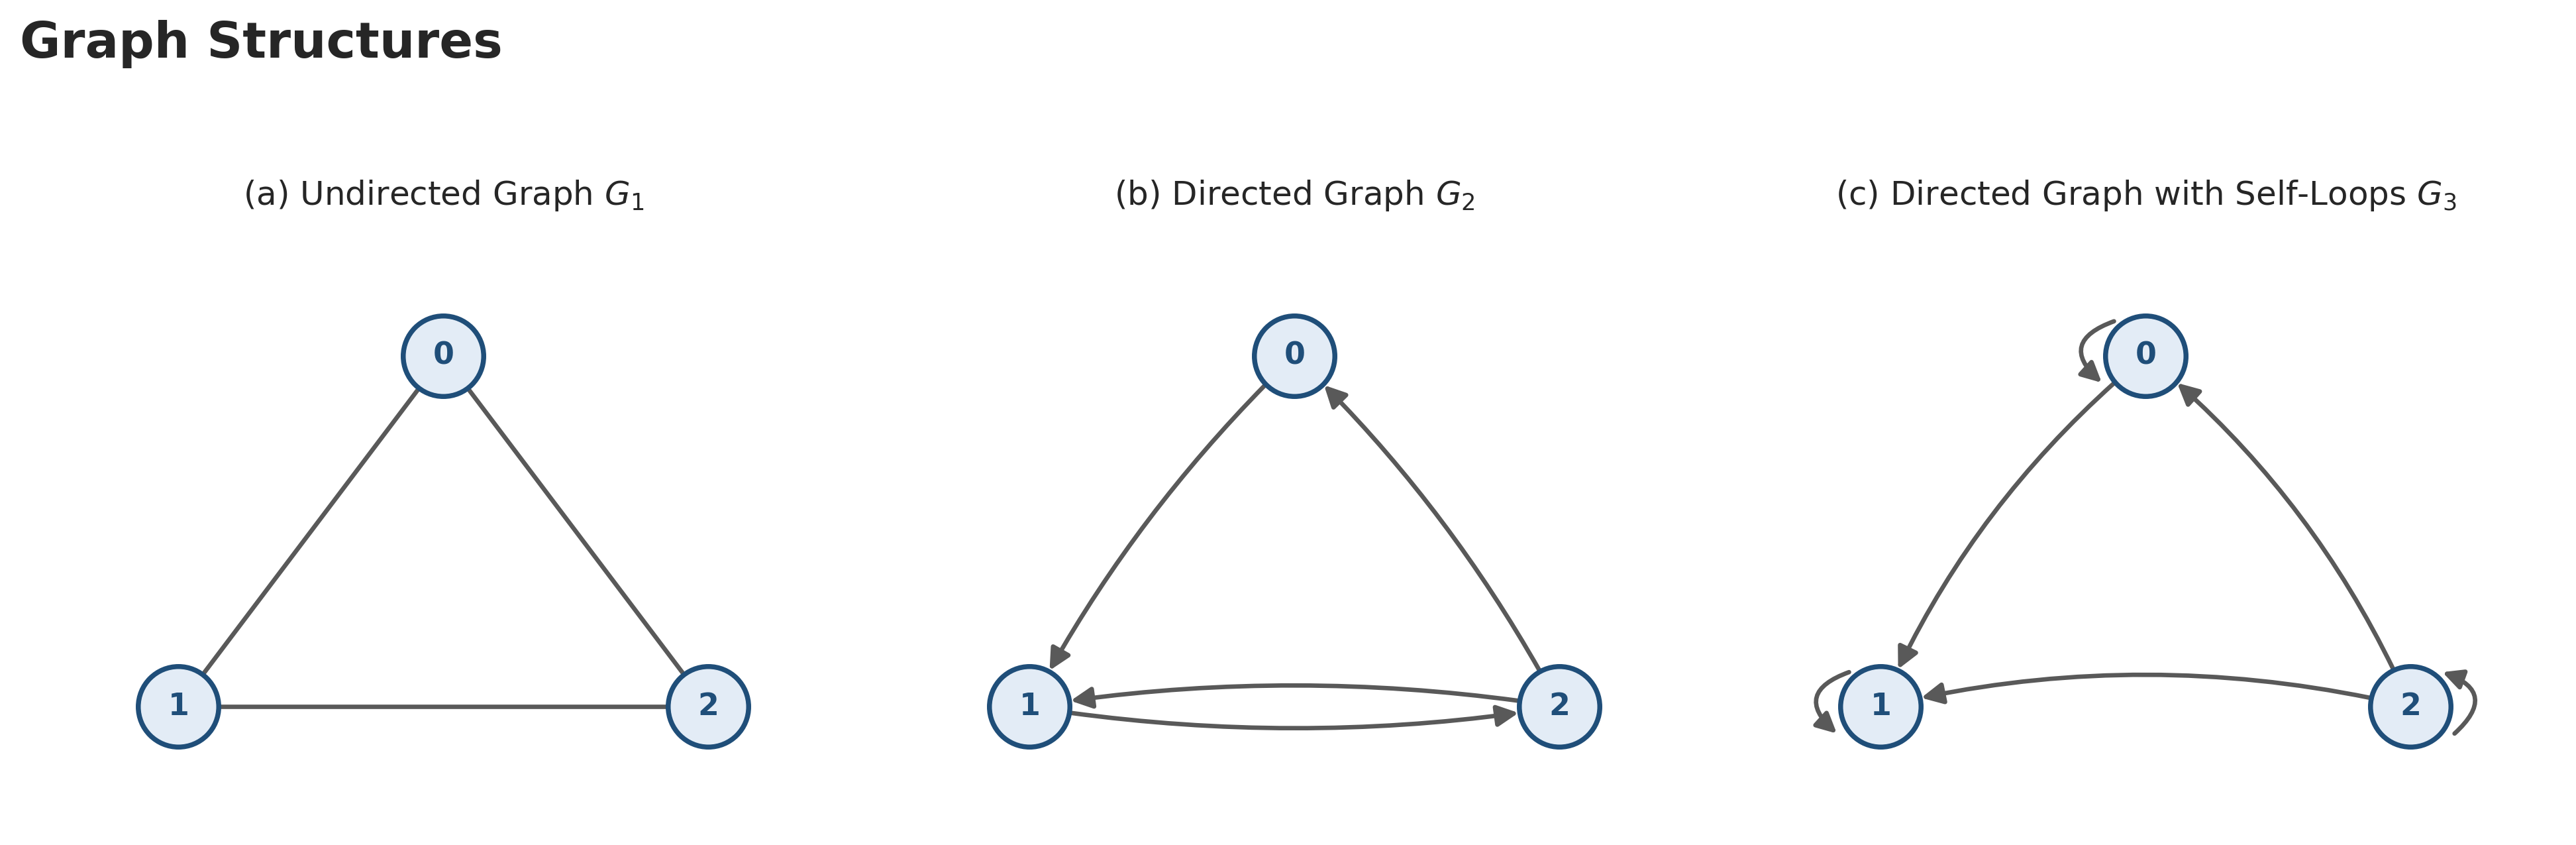

In [118]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

# -------------------------------------------------
# 1. Define Graphs
# -------------------------------------------------

# 1. Undirected graph
G1 = nx.Graph([(0, 1), (1, 2), (2, 0)])

# 2. Directed graph
G2 = nx.DiGraph([(0, 1), (1, 2), (2, 0), (2,1)])

# 3. Directed graph with self-loops & bidirectional edges
G3 = nx.DiGraph([
    (0, 1), (2, 1), (2, 0),
    (0, 0), (1, 1), (2, 2)
])

# Node positions
pos = {
    0: (0.0, 0.866),
    1: (-1.0, -0.866),
    2: (1.0, -0.866)
}

# -------------------------------------------------
# 2. Visualization Setup
# -------------------------------------------------

plt.rcParams['text.usetex'] = False
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), dpi=300)

# Aesthetics
node_opts = {"node_color": "#E3ECF6", "edgecolors": "#1F4E79", "node_size": 850,"linewidths": 1.8}

label_opts = {"font_size": 11,"font_color": "#1F4E79","font_weight": "bold","font_family": "sans-serif"}

edge_color = "#595959"

titles = [r"(a) Undirected Graph $G_1$",r"(b) Directed Graph $G_2$", r"(c) Directed Graph with Self-Loops $G_3$"]

graphs = [G1, G2, G3]

# -------------------------------------------------
# 3. Overall Figure Title
# -------------------------------------------------

fig.suptitle( "Graph Structures",fontsize=18, fontweight="bold", color="#262626", y=1,x=0.1)

# -------------------------------------------------
# 4. Plotting Loop
# -------------------------------------------------

for i, (G, ax, title) in enumerate(zip(graphs, axes, titles)):

    # ---------------------------------------------
    # Draw Nodes & Labels
    # ---------------------------------------------

    nx.draw_networkx_nodes(
        G, pos, ax=ax, **node_opts
    )

    nx.draw_networkx_labels(
        G, pos, ax=ax, **label_opts
    )

    # ---------------------------------------------
    # Graph 1: Undirected
    # ---------------------------------------------

    if i == 0:

        nx.draw_networkx_edges( G, pos, ax=ax, edge_color=edge_color, width=1.6)

    # ---------------------------------------------
    # Graph 2: Directed
    # ---------------------------------------------

    elif i == 1:

        nx.draw_networkx_edges( G, pos, ax=ax, edge_color=edge_color, width=1.6, arrows=True, arrowsize=16, arrowstyle="-|>", min_source_margin=15, min_target_margin=15, connectionstyle="arc3,rad=0.08")

    # ---------------------------------------------
    # Graph 3: Directed + Self-Loops
    # ---------------------------------------------

    else:

        # -----------------------------------------
        # Non-self directed edges
        # -----------------------------------------

        non_self_edges = [(u, v) for u, v in G.edges() if u != v]

        nx.draw_networkx_edges( G, pos, ax=ax, edgelist=non_self_edges, edge_color=edge_color, width=1.6, arrows=True, arrowsize=16, arrowstyle="-|>", min_source_margin=15, min_target_margin=15, connectionstyle="arc3,rad=0.12")

        # -----------------------------------------
        # Explicit self-loops
        # -----------------------------------------

        loop_size = 0.8

        for node in [0, 1, 2]:

            x, y = pos[node]

            # Position the loop differently for each node
            if node == 0:
                # Top node: loop above
                start = (x - 0.1, y + 0.18)
                end = (x - 0.15, y - 0.15)

            elif node == 1:
                # Bottom-left: loop to the left
                start = (x - 0.1, y + 0.18)
                end = (x - 0.15, y - 0.15)

            else:
                # Bottom-right: loop to the right
                start = (x + 0.15, y - 0.15)
                end = (x + 0.1, y + 0.18)

            loop = FancyArrowPatch(
                start,
                end,
                arrowstyle="-|>",
                mutation_scale=15,
                linewidth=1.6,
                color=edge_color,
                connectionstyle=f"arc3,rad=0.9"
            )

            ax.add_patch(loop)

    # ---------------------------------------------
    # Subplot Formatting
    # ---------------------------------------------

    ax.set_title(
        title,
        fontsize=12,
        pad=12,
        color="#262626"
    )

    ax.axis("off")

    # Extra space for loops
    ax.set_xlim(-1.55, 1.55)
    ax.set_ylim(-1.45, 1.45)


# -------------------------------------------------
# 5. Final Layout
# -------------------------------------------------

plt.tight_layout(rect=[0, 0, 1, 0.94])

plt.savefig(
    'outputs/GRAPHS/FIG1.png',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

plt.show()

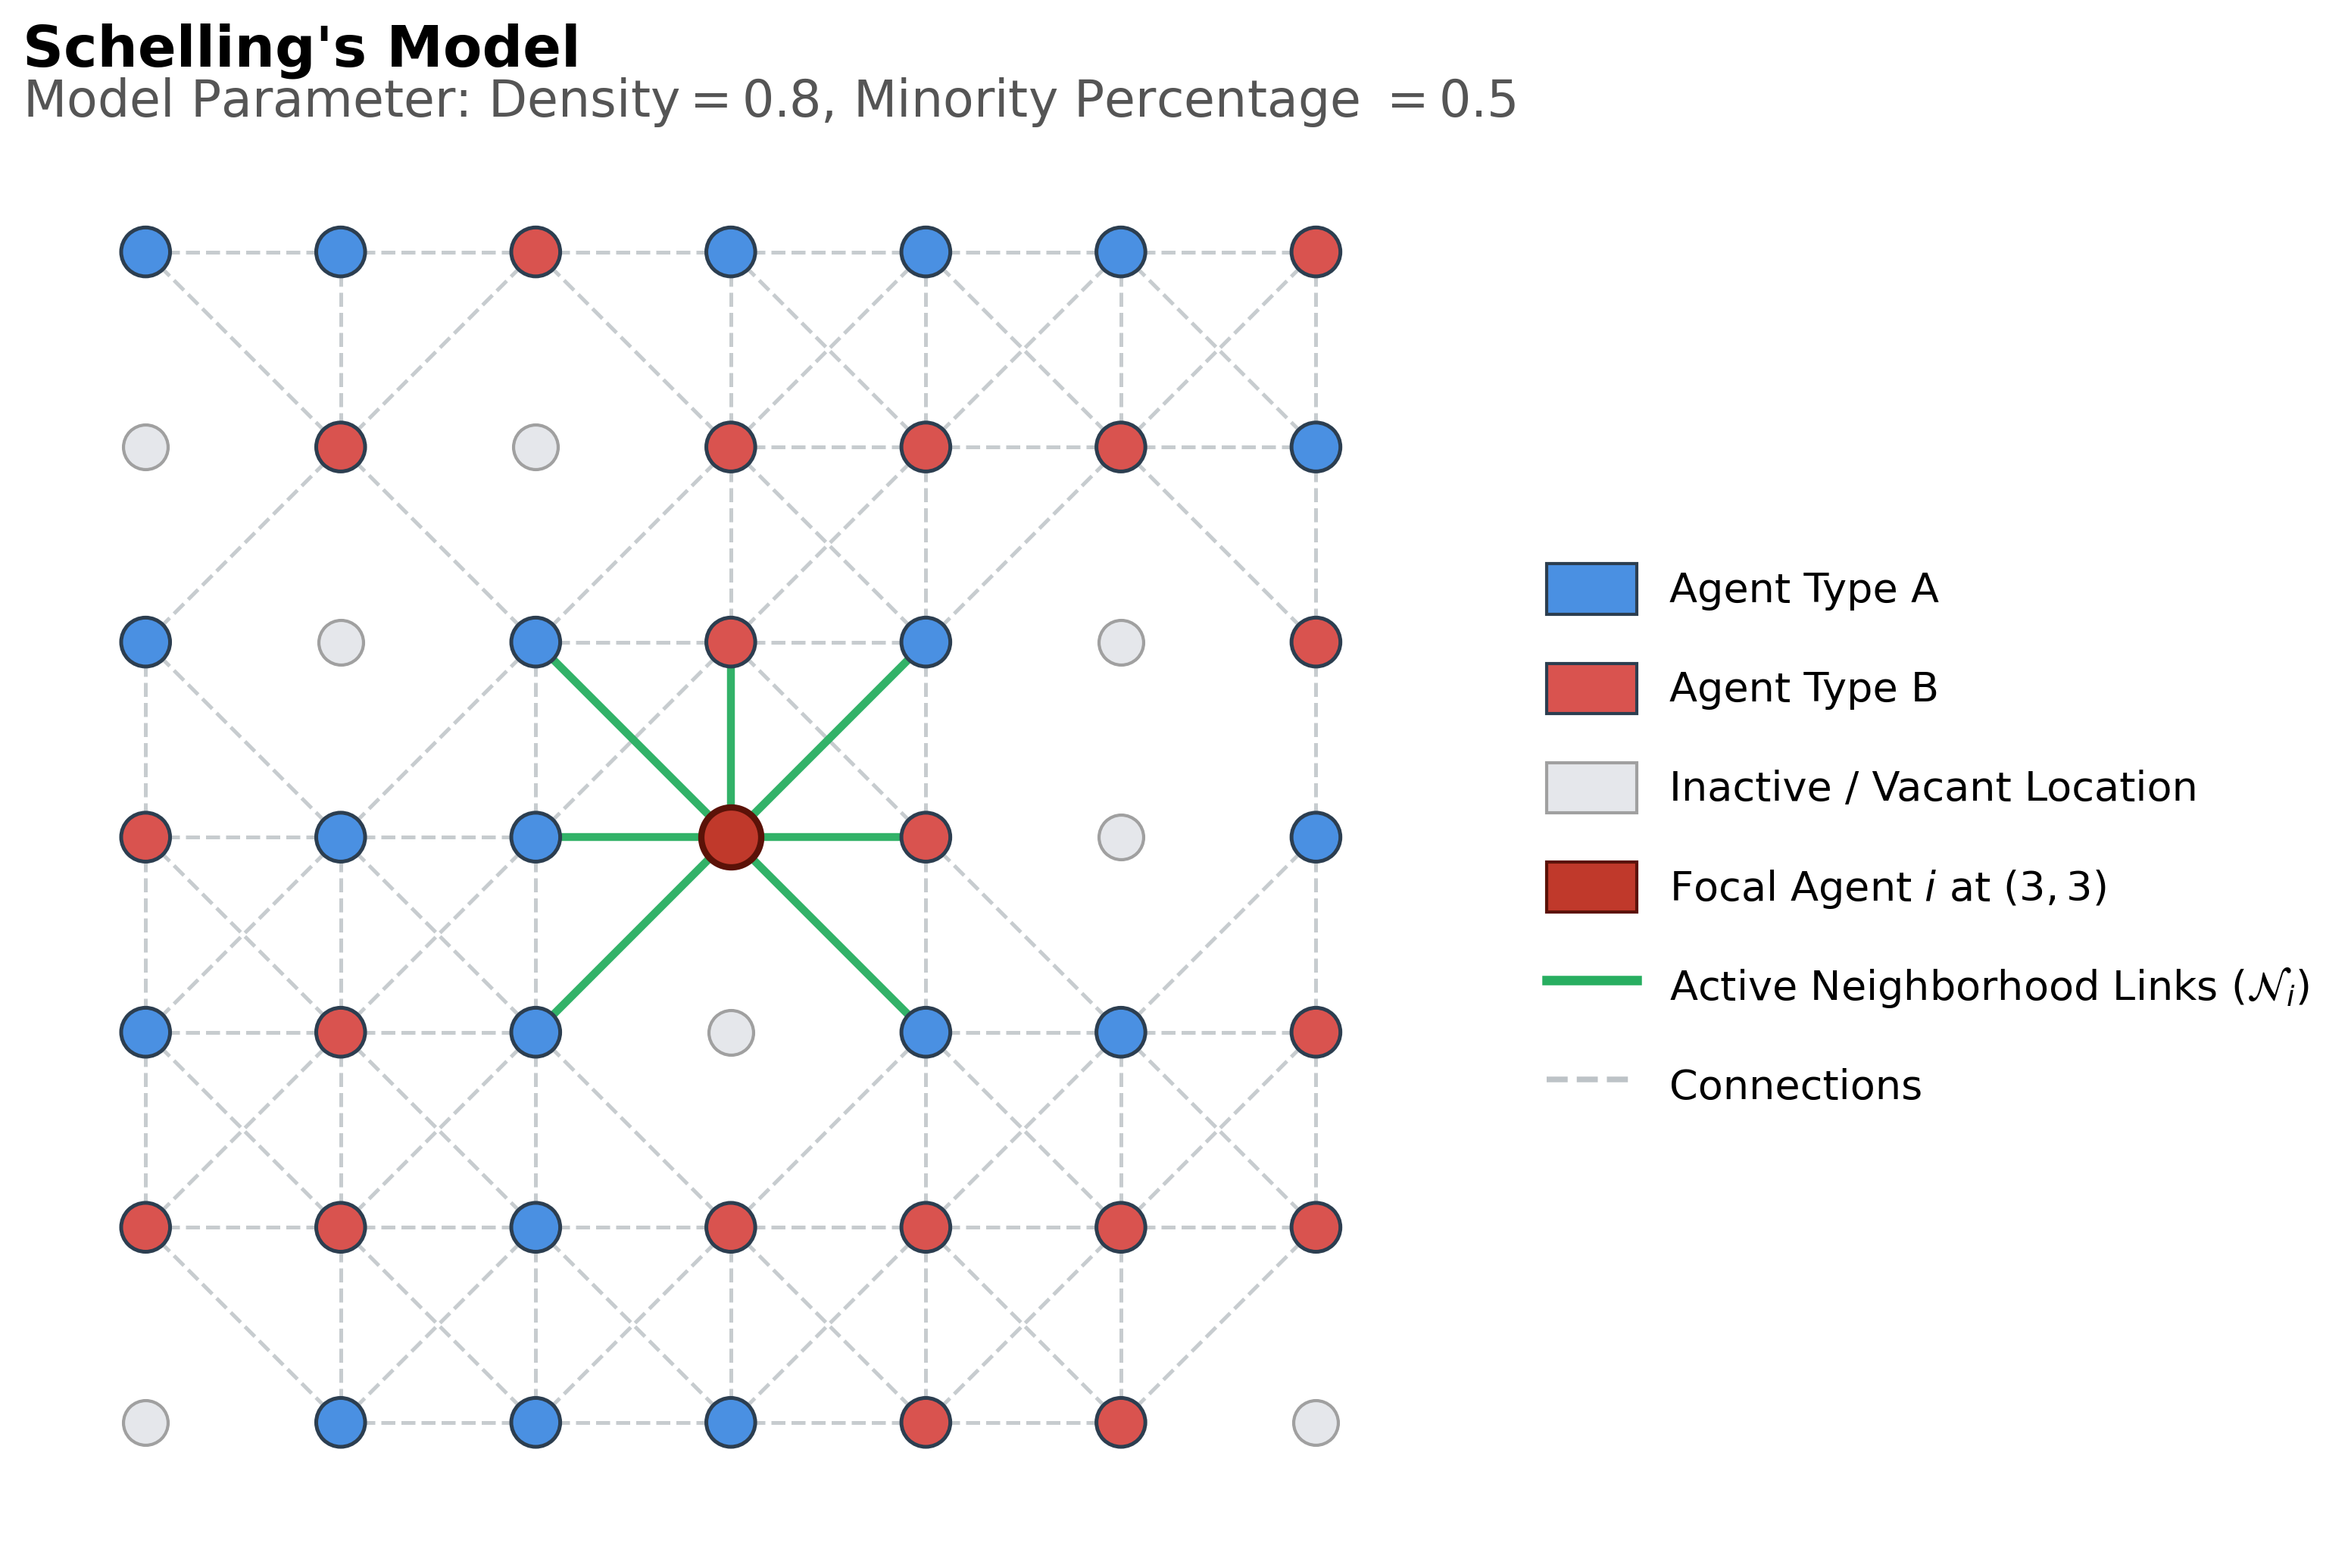

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import random

# -------------------------------------------------
# 1. Graph Generation & Seed Setup
# -------------------------------------------------
random.seed(1)

# Create 7x7 spatial grid lattice
G = nx.grid_2d_graph(7, 7)

# Add diagonal neighborhood connections (8-neighbor Moore neighborhood)
for x in range(6):
    for y in range(6):
        G.add_edge((x, y), (x + 1, y + 1))
        G.add_edge((x, y + 1), (x + 1, y))

# -------------------------------------------------
# 2. Node State Assignment
# -------------------------------------------------
node_colors = {}
inactive_nodes = set()
active_nodes = set()

# Color definitions (Academic Palette)
COLOR_TYPE_A = "#4A90E2"     # Muted Steel Blue
COLOR_TYPE_B = "#D9534F"     # Pastel Crimson
COLOR_INACTIVE = "#E5E7EB"   # Soft Neutral Gray
COLOR_FOCUS = "#C0392B"      # Deep Carmine Red (Selected Agent)
COLOR_EDGE_MAIN = "#BDC3C7"  # Muted Gray for grid edges
COLOR_EDGE_FOCUS = "#27AE60" # Emerald Green for focal connections

for node in G.nodes():
    # 20% probability of being inactive/vacant
    if random.random() < 0.2:
        node_colors[node] = COLOR_INACTIVE
        inactive_nodes.add(node)
    else:
        active_nodes.add(node)
        # 50/50 split for active agent types
        if random.random() < 0.5:
            node_colors[node] = COLOR_TYPE_A
        else:
            node_colors[node] = COLOR_TYPE_B

# Focal node at (3, 3)
selected = (3, 3)
active_nodes.add(selected)
node_colors[selected] = COLOR_FOCUS

# Filter edges: only connections between active agents
active_edges = [(u, v) for u, v in G.edges() if u in active_nodes and v in active_nodes]
focus_edges = [(selected, neighbor) for neighbor in G.neighbors(selected) if neighbor in active_nodes]
background_active_edges = [e for e in active_edges if e not in focus_edges and (e[1], e[0]) not in focus_edges]

# Spatial coordinate layout
pos = {(x, y): (x, y) for x, y in G.nodes()}

# -------------------------------------------------
# 3. Visualization Setup
# -------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 7), dpi=300)

# Draw Inactive / Vacant Nodes (Dashed Border)
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    nodelist=list(inactive_nodes),
    node_color=COLOR_INACTIVE,
    edgecolors="#A0A0A0",
    node_size=200,
    linewidths=1.0
)

# Draw Active Background Nodes
active_bg_nodes = [n for n in active_nodes if n != selected]
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    nodelist=active_bg_nodes,
    node_color=[node_colors[n] for n in active_bg_nodes],
    edgecolors="#2C3E50",
    node_size=240,
    linewidths=1.2
)

# Draw Background Active Edges (Dashed)
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edgelist=background_active_edges,
    edge_color=COLOR_EDGE_MAIN,
    style="dashed",
    width=1.2,
    alpha=0.85
)

# Draw Focal Neighborhood Edges (Solid Emerald Green)
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edgelist=focus_edges,
    edge_color=COLOR_EDGE_FOCUS,
    style="solid",
    width=2.5,
    alpha=0.95
)

# Draw Focal Selected Agent Node
nx.draw_networkx_nodes(
    G, pos, ax=ax,
    nodelist=[selected],
    node_color=COLOR_FOCUS,
    edgecolors="#5B1208",
    node_size=360,
    linewidths=2.0
)

ax.set_title("Schelling's Model", loc="left", fontweight="bold", pad=20, fontsize=18)
ax.text(
    0, 1, r"Model Parameter: Density$ = 0.8$, Minority Percentage $= 0.5$",
    transform=ax.transAxes, fontsize=16, ha="left", va="bottom", color="#555555"
)

# Plot formatting
ax.axis("off")
ax.set_aspect("equal")

# -------------------------------------------------
# 4. Larger Legend (Positioned Right, No Background)
# -------------------------------------------------
legend_handles = [
    mpatches.Patch(color=COLOR_TYPE_A, ec="#2C3E50", label="Agent Type A"),
    mpatches.Patch(color=COLOR_TYPE_B, ec="#2C3E50", label="Agent Type B"),
    mpatches.Patch(color=COLOR_INACTIVE, ec="#A0A0A0", label="Inactive / Vacant Location"),
    mpatches.Patch(color=COLOR_FOCUS, ec="#5B1208", label="Focal Agent $i$ at $(3,3)$"),
    mlines.Line2D([], [], color=COLOR_EDGE_FOCUS, lw=3.0, label=r"Active Neighborhood Links $(\mathcal {N}_i)$"),
    mlines.Line2D([], [], color=COLOR_EDGE_MAIN, lw=1.8, ls="--", label="Connections")
]

ax.legend(
    handles=legend_handles,
    loc="center left",
    bbox_to_anchor=(1.05, 0.5),  # Shifted slightly right to make room for larger font
    ncol=1,
    frameon=False,
    fontsize=13,                # Increased font size (from 9.5 to 13)
    labelspacing=1.2,           # Extra vertical spacing between items
    handlelength=2.2,           # Longer line/patch handles
    handleheight=1.5            # Taller patch handles
)

plt.tight_layout()

# Save publication-quality figures
plt.savefig('outputs/SHEL/FIG1.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

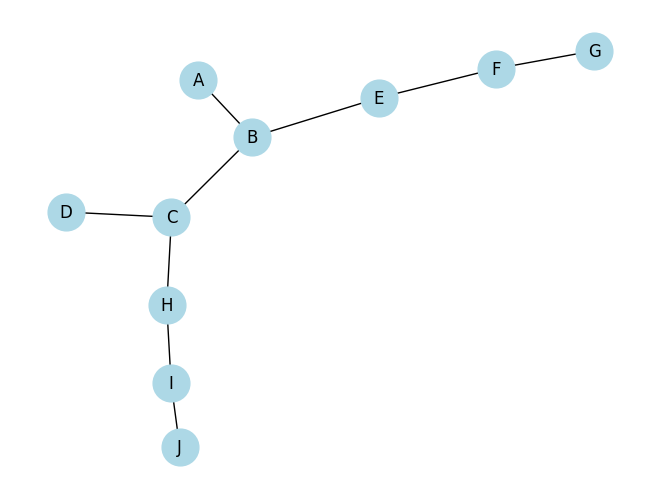

In [6]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

# Main branch
G.add_edges_from([
    ("A", "B"),
    ("B", "C"),
    ("C", "D"),
])

# Branch coming from B
G.add_edges_from([
    ("B", "E"),
    ("E", "F"),
    ("F", "G"),
])

# Another branch coming from C
G.add_edges_from([
    ("C", "H"),
    ("H", "I"),
    ("I", "J"),
])

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=700,
    node_color="lightblue"
)

plt.show()

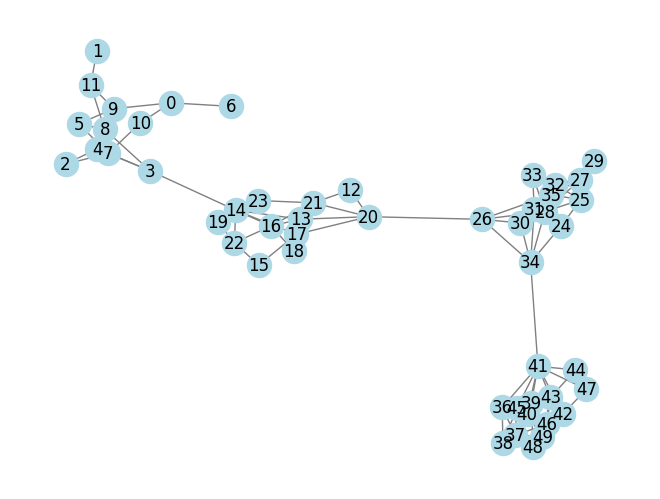

In [22]:
import networkx as nx
import matplotlib.pyplot as plt
import random

# -------------------------
# Parameters
# -------------------------

n = 50

number_of_clusters = 4

p_inside = 0.30       # probability of connections within clusters
connections_between = 1  # number of connections between clusters


# -------------------------
# Create clusters
# -------------------------

cluster_size = n // number_of_clusters

sizes = [cluster_size] * number_of_clusters
sizes[-1] += n - sum(sizes)


# -------------------------
# Create each cluster
# -------------------------

clusters = []

for size in sizes:

    # Keep generating until nobody is isolated
    while True:

        cluster = nx.gnp_random_graph(size, p_inside)

        # Check that everybody has at least one connection
        if all(cluster.degree(node) >= 1 for node in cluster.nodes()):
            break

    clusters.append(cluster)


# -------------------------
# Combine clusters
# -------------------------

G = nx.disjoint_union_all(clusters)


# -------------------------
# Connect the clusters
# -------------------------

cluster_nodes = []

start = 0

for size in sizes:
    nodes = list(range(start, start + size))
    cluster_nodes.append(nodes)
    start += size


for i in range(number_of_clusters - 1):

    # Choose one random individual from each cluster
    node1 = random.choice(cluster_nodes[i])
    node2 = random.choice(cluster_nodes[i + 1])

    G.add_edge(node1, node2)


# -------------------------
# Draw network
# -------------------------

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=300,
    node_color="lightblue",
    edge_color="gray"
)

plt.show()

# Basic Class

The model is structured around a sequence of three periods . This temporal structure is intended to capture, in a deliberately simplified manner, the interaction between households, banks, and firms, without requiring firms to be explicitly represented as individual agents in the model. Instead, firms are treated as an implicit counterpart to the banking sector: banks allocate part of their assets to firms during the first period and receive repayment, including a stochastic return, during the third period.

At the beginning of each day, households hold wealth in two forms: cash and bank deposits. During the first period, households decide how much of their available cash to deposit in the bank. A deposit therefore represents a transfer of liquid resources from the household to the banking sector. From the household's perspective, the composition of its wealth changes, as cash holdings decrease while deposits increase, leaving total wealth unchanged. From the bank's perspective, the transaction simultaneously increases its liquid assets and its liabilities, since deposits constitute an obligation of the bank toward its depositors.

At the end of the first period, the bank allocates its available liquid assets between reserves and loans to firms. The bank is assumed to maintain a predetermined fraction of its liabilities as reserves, represented by the reserve ratio. Any liquid assets in excess of the required reserves are implicitly lent to firms. Firms are not explicitly modelled as agents; consequently, the loan relationship is represented directly through the bank's balance sheet. The corresponding amount is reclassified from liquid to illiquid assets. This operation does not change the total value of the bank's assets, liabilities, or equity; rather, it changes the composition of the asset side of the balance sheet. The bank therefore enters the second period holding a relatively small stock of liquid reserves and a larger stock of illiquid claims on firms.

During the second period, households are exposed to idiosyncratic consumption shocks. A household experiencing a sufficiently large consumption shock may require more cash than it currently holds and therefore seek to withdraw funds from its bank deposit before the end of the period. Early withdrawal is costly: the amount that the household can effectively obtain is reduced by a predetermined early-withdrawal discount. Thus, if a household has a deposit of (D) and the early-withdrawal discount is (\delta), the maximum amount it can receive through an early withdrawal is given by

[
W^{\max} = D(1-\delta).
]

Early withdrawals are financed exclusively through the bank's available liquid reserves. This creates a direct link between the liquidity position of the banking sector and the ability of households to respond to unexpected consumption needs. In particular, although the bank may hold substantial total assets, its ability to meet early withdrawal requests is constrained by the fraction of those assets that remains liquid. The illiquid assets corresponding to loans to firms cannot be immediately used to satisfy withdrawal requests within this period.

The early-withdrawal discount also generates a transfer between households and the banking sector. The household receives less than the nominal value of the deposit withdrawn, while the difference is retained by the bank and interpreted as a cost associated with early withdrawal. Consequently, early withdrawals reduce the bank's deposit liabilities by the nominal amount withdrawn while increasing bank equity by the corresponding penalty. This mechanism introduces a simple trade-off for households: maintaining funds in the bank allows them to retain their full nominal value, whereas accessing those funds prematurely provides liquidity at a cost.

In the third and final period, the firms implicitly represented in the model repay the funds previously borrowed from the banking sector. The repayment consists of the original principal plus a return that is assumed to be stochastic. If the amount lent by the bank is (L) and the realized return is (r), the repayment received by the bank is

[
R = L(1+r).
]

The repayment transforms the bank's previously illiquid claims into liquid assets. The stochastic component of the return therefore introduces an additional source of variation in bank profitability and liquidity across periods. The return above the principal represents income accruing to the bank and, consequently, increases its equity.

Following the repayment by firms, the bank settles the remaining claims of depositors. Households that did not withdraw their deposits during the second period receive the corresponding value of their remaining deposits. The daily cycle therefore concludes with households holding a combination of cash and deposits, while the bank holds its new stock of liquid assets, has settled its outstanding short-term obligations to households, and records any profits or losses generated by its lending activity and early-withdrawal penalties.

Overall, the mechanism provides a simplified representation of the interaction between **household liquidity management, bank liquidity transformation, and firm financing**. The central feature is the distinction between liquid and illiquid bank assets. Deposits provide households with a liquid claim on the banking sector, while the bank transforms part of these liabilities into illiquid claims on firms. This transformation generates a potential maturity and liquidity mismatch: the bank's total assets may be sufficient to cover its liabilities, while its immediately available liquid assets may nevertheless be insufficient to satisfy all withdrawal requests. The three-period structure allows this mechanism to emerge endogenously from the sequence of household deposits, unexpected consumption needs, and subsequent repayment of firm loans.
